# Vault Ledger: model experiments (November 2026)

This notebook summarises every classifier test run after the public data was collected. It reads saved results
from `notebooks/results/` and does not retrain anything. The scripts that produced them are in `notebooks/experiments/`.

**How to read the numbers**

| Metric | Meaning |
|---|---|
| **Accuracy** | share of transactions where the first suggestion is the right account |
| **Macro F1** | average quality over the 7 accounts, each account counting equally, so a rare account like Rent counts as much as General. 1.0 is perfect. This is the main score. |
| **Top-2** | share where the right account is among the two best suggestions, i.e. fixable with one click in the review screen |
| **Coverage @95%** | share of transactions the model is confident enough about to be 95% right, i.e. what could skip review |

**The three test sets** (no model was trained or tuned on them)

| Test set | What it is | Stands for |
|---|---|---|
| Synthetic test | 1,511 rows of our own generated Dutch/English invoices, vendors unseen in training | our target documents |
| Real public data | 15–26k real business transactions (UK/US/NL government spend, card statements), vendors unseen in training | real-world wording |
| ZeraBooks | 1,568 bank-statement lines, no vendor field | bank feeds |

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
R = Path('results')
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25,
                     'figure.dpi': 110, 'axes.axisbelow': True})
load = lambda n: json.loads((R / n).read_text())
def bars(df, title, ylabel='macro F1', ylim=(0, .8)):
    ax = df.plot.bar(figsize=(11, 4), color=PAL[:df.shape[1]], width=.8, edgecolor='white', linewidth=2)
    ax.set_title(title, loc='left', fontweight='bold'); ax.set_ylabel(ylabel); ax.set_ylim(*ylim); ax.set_xlabel('')
    for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7, padding=2)
    plt.xticks(rotation=20, ha='right'); ax.legend(frameon=False, ncols=df.shape[1], loc='upper left'); plt.tight_layout(); plt.show()

## 1. TF-IDF model variants

Six variants of the fast text model, all trained on synthetic data plus about 120k public business rows.

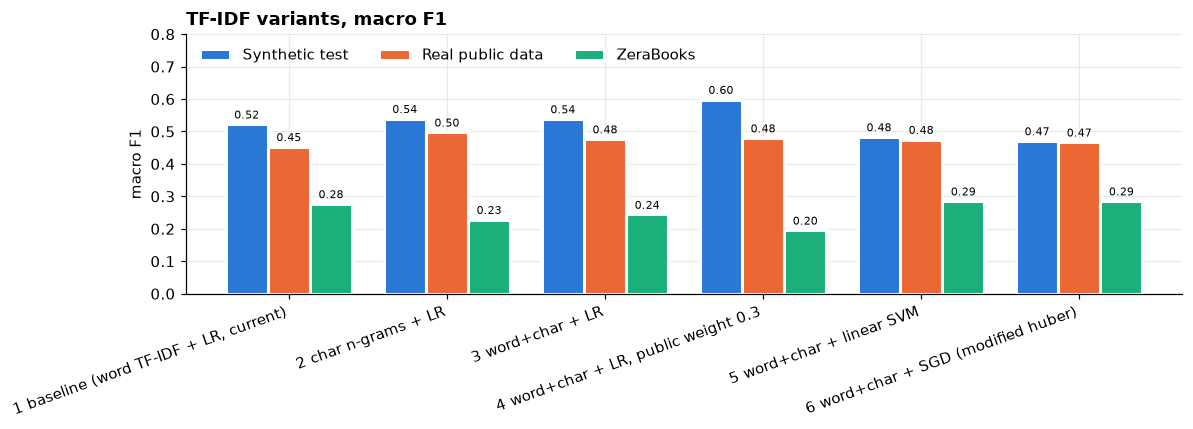

,synthetic acc,real acc,real top-2,ZeraBooks acc,train seconds,"ms per 1,000 txns"
"1 baseline (word TF-IDF + LR, current)",0.61,0.57,0.84,0.40,21.67,8.10
2 char n-grams + LR,0.62,0.61,0.86,0.38,96.65,36.32
3 word+char + LR,0.62,0.57,0.86,0.39,102.40,48.91
"4 word+char + LR, public weight 0.3",0.67,0.59,0.86,0.36,66.61,57.52
5 word+char + linear SVM,0.57,0.57,0.85,0.42,22.27,46.85
6 word+char + SGD (modified huber),0.55,0.56,0.81,0.41,13.71,49.06


In [2]:
b = load('bench.json'); d = pd.DataFrame(b['results']).T
f1 = d[['synthetic_f1', 'external_real_f1', 'zerabooks_f1']]; f1.columns = ['Synthetic test', 'Real public data', 'ZeraBooks']
bars(f1, 'TF-IDF variants, macro F1')
show = d[['synthetic_acc', 'external_real_acc', 'external_real_top2', 'zerabooks_acc', 'fit_s', 'ms_per_1000']].copy()
show.columns = ['synthetic acc', 'real acc', 'real top-2', 'ZeraBooks acc', 'train seconds', 'ms per 1,000 txns']
show.style.format('{:.2f}')

**Findings**
- The differences between model types are small (±0.05). The training data matters more than the model type.
- Character pieces (variant 2) are best on real data (0.50); weighting public data at 0.3 (variant 4) is best on synthetic data (0.60).
- All variants classify 1,000 transactions in under 0.06 seconds.

## 2. Five-fold check, unseen vendors in every fold

All real public rows are split into 5 parts by vendor, so no vendor appears in both training and testing. Each part
is tested once. The spread between folds shows how much a score can move by chance.

In [3]:
cv = pd.DataFrame({k: {m: f'{v[0]:.3f} ± {v[1]:.3f}' for m, v in r.items()} for k, r in b['cv'].items()}).T
cv

,acc,f1,top2,cov@90,cov@95
"1 baseline (word TF-IDF + LR, current)",0.621 ± 0.040,0.454 ± 0.014,0.835 ± 0.007,0.247 ± 0.032,0.164 ± 0.031
5 word+char + linear SVM,0.637 ± 0.033,0.483 ± 0.015,0.832 ± 0.010,NaN,NaN


**Findings**: the current model scores 0.454 ± 0.014 F1 and 83% top-2. The SVM gains 0.03, about twice the spread
between folds, so the gain is real but small. **The 83% top-2 figure is the most robust number we have.**

## 3. DragoNet (the main model) on real data

The DragoNet models had only been tested on synthetic data. Here they get the same tests. `new` is retrained with
10.6k public rows added (23 minutes of training).

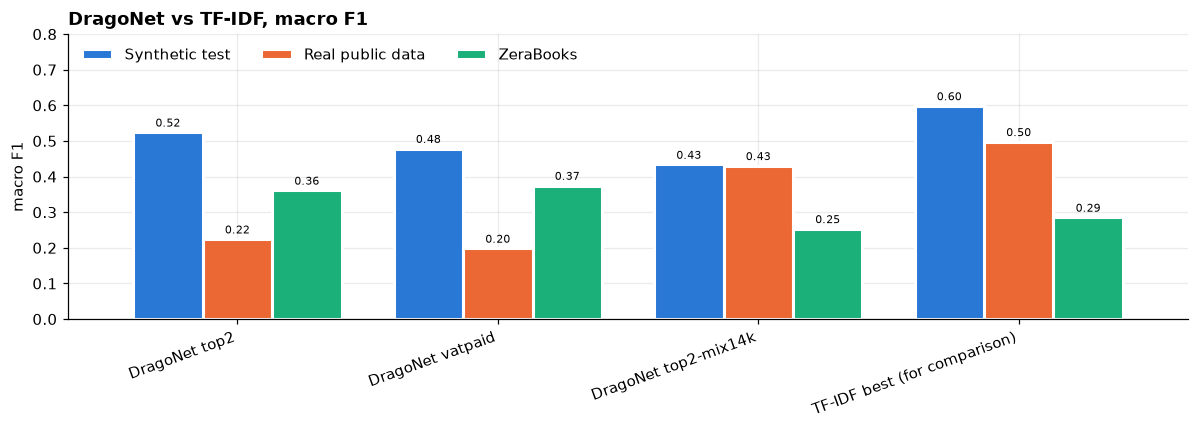

In [4]:
rows = {}
for fn in ('dragonet_eval.json', 'dragonet_mix.json'):
    for k, v in load(fn).items():
        run, test = [x.strip() for x in k.split('|')]
        rows.setdefault(run.replace('synth-crew-2026-pretrained-', 'DragoNet '), {})[test.split(' (')[0]] = v['f1']
dn = pd.DataFrame(rows).T[['synthetic', 'external_real', 'zerabooks']]
dn.loc['TF-IDF best (for comparison)'] = [f1.iloc[3, 0], f1.iloc[1, 1], f1.iloc[4, 2]]
dn.columns = ['Synthetic test', 'Real public data', 'ZeraBooks']
bars(dn, 'DragoNet vs TF-IDF, macro F1')

**Findings**
- Trained only on synthetic data, DragoNet scores about 0.2 on real data: it has overfitted to our synthetic data.
- It is the best model on bank lines (0.36–0.375); the multilingual encoder handles statement text well.
- Adding public data doubles its real-data score (0.22 → 0.43) but costs synthetic (0.53 → 0.43) and bank lines
  (0.36 → 0.25). The public rows have no date, paid flag or VAT, so the model probably learned "missing fields means
  public-style label" (not tested yet).
- *Note:* these tests give DragoNet only vendor + description + amount, with no real date, paid flag or VAT, so its
  synthetic score is lower than the 0.59 in its own report.

## 4. Combining the models

Members: TF-IDF (variant 4), DragoNet old, DragoNet new. Weights and the stacker were tuned only on calibration data
(synthetic validation split + 40% of the real-data vendors). The remaining 60% and ZeraBooks were left untouched.

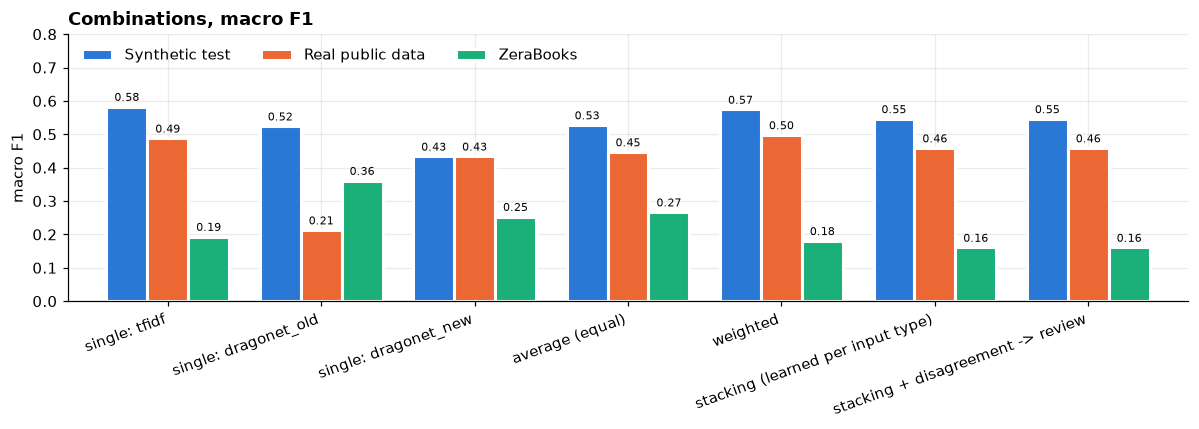

,Synthetic test,Real public data,ZeraBooks
single: tfidf,80%,87%,53%
single: dragonet_old,68%,49%,46%
single: dragonet_new,68%,79%,69%
average (equal),79%,79%,70%
weighted,79%,86%,64%
stacking (learned per input type),77%,86%,48%
stacking + disagreement -> review,77%,86%,48%


In [5]:
e = load('ensemble.json')
ens = pd.DataFrame({k.split(' {')[0]: {t: r['f1'] for t, r in v.items()} for k, v in e.items()}).T
ens.columns = ['Synthetic test', 'Real public data', 'ZeraBooks']
bars(ens, 'Combinations, macro F1')
top2 = pd.DataFrame({k.split(' {')[0]: {t: r['top2'] for t, r in v.items()} for k, v in e.items()}).T
top2.columns = ens.columns; top2.style.format('{:.0%}').set_caption('Top-2')

**Findings**
- The best combination is the **weighted average (TF-IDF 0.6, DragoNet new 0.3, DragoNet old 0.1)**: real data 0.50 F1,
  64% accuracy, 86% top-2. It gains little over TF-IDF alone (+0.01).
- Stacking was worse: it learned the calibration data's patterns too closely and didn't carry over.
- **Edge case: bank lines.** The calibration data has no bank lines, so every combination learned to trust TF-IDF,
  which is weak there. DragoNet old alone stays best on ZeraBooks (0.36).
- **Recommendation: choose by input type.** Weighted blend when there is a vendor name; DragoNet old for bank lines with
  no vendor.

## 5. Changeable chart of accounts

Every customer has different accounts. One model was trained on 29 detailed categories (cloud hosting, telecom,
notary, fuel, ...). Its answers were then grouped into different account sets without retraining, and compared
with a model retrained for each set.

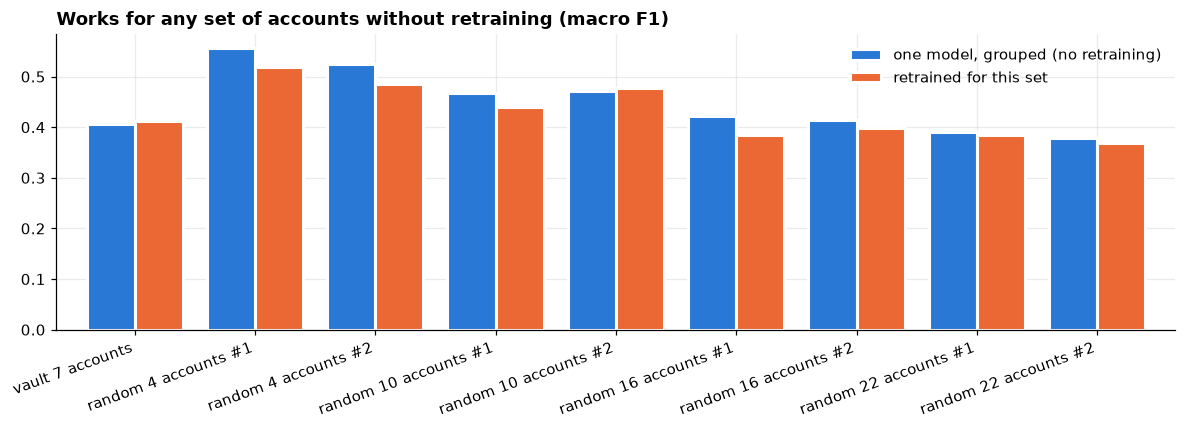

In [6]:
a = load('adaptive.json'); ch = pd.DataFrame(a['charts'])
ax = ch[ch.retrained_f1.notna()].plot(x='chart', y=['rollup_f1', 'retrained_f1'], kind='bar', figsize=(11, 4),
     color=PAL[:2], width=.8, edgecolor='white', linewidth=2)
ax.legend(['one model, grouped (no retraining)', 'retrained for this set'], frameon=False)
ax.set_title('Works for any set of accounts without retraining (macro F1)', loc='left', fontweight='bold')
ax.set_xlabel(''); plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

In [7]:
na = pd.DataFrame(a['new_account']).pivot(index='new_account', columns='examples', values='recall_new')
na.style.format('{:.0%}').set_caption('Brand-new account: share of its transactions found, by number of examples given')

examples,5,20,100
new_account,,,
advertising,1%,0%,11%
air_travel,97%,96%,97%
coworking,0%,0%,0%
furniture,0%,0%,0%
legal_notary,3%,1%,0%
telecom,3%,0%,1%


**Findings**
- Grouping one detailed model is as good as or better than retraining, on 8 of 9 account sets. **A customer's
  accounts only need to be linked once to the detailed categories (via RGS codes for Dutch customers).**
- A brand-new account can't be learned from a few corrections: only air travel worked. Corrections teach specific
  vendors, not the kind of expense. So corrections should feed vendor memory, and new accounts should be linked to
  detailed categories.

## 6. What is safe to use, and what is not

| Use in advertising | Evidence |
|---|---|
| "The right account is in the top 2 suggestions 83–86% of the time, even for vendors it has never seen" | 5-fold check (§2), combination test (§4) |
| "Works with your own chart of accounts, no retraining needed" | §5 |
| "Fast and fully offline: about 6 ms per transaction on a laptop" | timing in §1, §4 |

| Do not claim | Why |
|---|---|
| A headline accuracy figure | 57–66%, too low to headline |
| "Books automatically" | at 95% precision only about 13% of transactions could skip review |
| Anything about Dutch real data | there is no Dutch real test data yet |

## 7. Next steps

1. Put the input-type routing into the cascade: blend for vendor documents, DragoNet old for bank lines.
2. Retrain DragoNet on the 29 detailed categories, with the synthetic rows counted more heavily.
3. Get a small labelled Dutch set from a pilot customer: it's the only way to close the remaining gap and to make
   Dutch claims.
4. Check the licences of the public sources before training a model we sell.